Saving DataCoSupplyChainDataset.csv.zip to DataCoSupplyChainDataset.csv.zip
Dataset loaded successfully!
Shape: (180519, 53)

First 5 rows:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer

,0
Product Description,180519
Order Zipcode,155679
Customer Lname,8
Customer Zipcode,3



Duplicate rows: 0

Target distribution:


,count
Late_delivery_risk,
1,98977
0,81542



Target percentage:


,proportion
Late_delivery_risk,
1,54.83
0,45.17


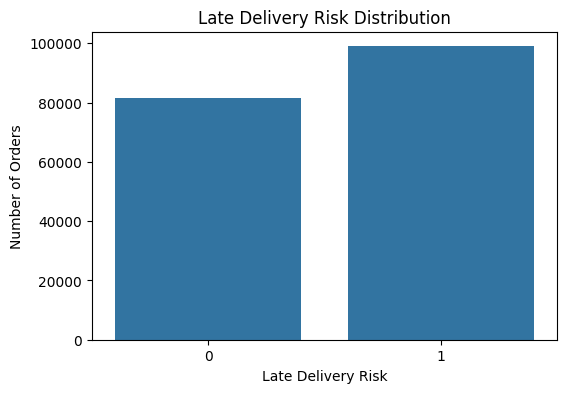

In [2]:
# STEP 1: Upload and load the dataset

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(
    file_name,
    encoding="unicode_escape"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
missing = df.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["Late_delivery_risk"].value_counts())

print("\nTarget percentage:")
display(
    df["Late_delivery_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Late_delivery_risk")
plt.title("Late Delivery Risk Distribution")
plt.xlabel("Late Delivery Risk")
plt.ylabel("Number of Orders")
plt.show()

In [3]:
# STEP 2: Data cleaning and feature selection

drop_columns = [
    'Days for shipping (real)',
    'Delivery Status',
    'Late_delivery_risk',
    'shipping date (DateOrders)',
    'Product Description',
    'Product Image',
    'Customer Email',
    'Customer Password',
    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    'Customer Zipcode',
    'Order Zipcode',
    'Order Id',
    'Order Item Id',
    'Order Customer Id',
    'Customer Id'
]

df_clean = df.drop(columns=drop_columns, errors='ignore').copy()

target = df['Late_delivery_risk']

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nRemaining columns:")
print(df_clean.columns.tolist())

print("\nMissing values after cleaning:")
missing = df_clean.isnull().sum()
display(missing[missing > 0])

print("\nTarget distribution:")
print(target.value_counts())

print("\nTarget percentage:")
print(target.value_counts(normalize=True).mul(100).round(2))

Original shape: (180519, 53)
Cleaned shape: (180519, 36)

Remaining columns:
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Card Id', 'Product Category Id', 'Product Name', 'Product Price', 'Product Status', 'Shipping Mode']

Missing values after cleaning:


,0



Target distribution:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Target percentage:
Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64


In [4]:
# STEP 3: Feature engineering and final feature selection

data = df_clean.copy()

data['order date (DateOrders)'] = pd.to_datetime(
    data['order date (DateOrders)'],
    errors='coerce'
)

data['order_year'] = data['order date (DateOrders)'].dt.year
data['order_month'] = data['order date (DateOrders)'].dt.month
data['order_day'] = data['order date (DateOrders)'].dt.day
data['order_dayofweek'] = data['order date (DateOrders)'].dt.dayofweek

data = data.drop(columns=['order date (DateOrders)'])

remove_columns = [
    'Order Item Cardprod Id',
    'Product Card Id',
    'Product Category Id',
    'Category Id',
    'Department Id',
    'Order Status',
    'Product Status'
]

data = data.drop(columns=remove_columns, errors='ignore')

features = [
    'Type',
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer',
    'Category Name',
    'Customer City',
    'Customer Country',
    'Customer Segment',
    'Customer State',
    'Department Name',
    'Latitude',
    'Longitude',
    'Market',
    'Order City',
    'Order Country',
    'Order Region',
    'Order State',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Profit Ratio',
    'Order Item Quantity',
    'Sales',
    'Order Item Total',
    'Order Profit Per Order',
    'Product Name',
    'Product Price',
    'Shipping Mode',
    'order_year',
    'order_month',
    'order_day',
    'order_dayofweek'
]

X = data[features].copy()
y = target.copy()

print("Final feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical features:")
print(X.select_dtypes(include='object').columns.tolist())

print("\nNumerical features:")
print(X.select_dtypes(exclude='object').columns.tolist())

print("\nFinal missing values:", X.isnull().sum().sum())

Final feature shape: (180519, 32)
Target shape: (180519,)

Categorical features:
['Type', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode']

Numerical features:
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Price', 'order_year', 'order_month', 'order_day', 'order_dayofweek']

Final missing values: 0


In [5]:
# STEP 4: Train-test split and preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=['object']
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=True
            ),
            categorical_features
        ),
        (
            'numerical',
            'passthrough',
            numerical_features
        )
    ]
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

print("\nCategorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Training samples: 144415
Testing samples: 36104

Training target distribution:
Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64

Testing target distribution:
Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64

Categorical features: 14
Numerical features: 18


In [7]:
# STEP 5: Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

dt_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42
        ))
    ]
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)
dt_auc = roc_auc_score(y_test, dt_prob)

print("Decision Tree Classifier Results")
print("--------------------------------")
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1 Score  : {dt_f1:.4f}")
print(f"ROC-AUC   : {dt_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["Not Late", "Late"]
))

Decision Tree Classifier Results
--------------------------------
Accuracy  : 0.7049
Precision : 0.8413
Recall    : 0.5692
F1 Score  : 0.6790
ROC-AUC   : 0.7499

Classification Report:
              precision    recall  f1-score   support

    Not Late       0.62      0.87      0.73     16308
        Late       0.84      0.57      0.68     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.74      0.70      0.70     36104



In [8]:
# STEP 6: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Classifier Results")
print("--------------------------------")
print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Not Late", "Late"]
))

Random Forest Classifier Results
--------------------------------
Accuracy  : 0.6930
Precision : 0.7961
Recall    : 0.5916
F1 Score  : 0.6788
ROC-AUC   : 0.7564

Classification Report:
              precision    recall  f1-score   support

    Not Late       0.62      0.82      0.71     16308
        Late       0.80      0.59      0.68     19796

    accuracy                           0.69     36104
   macro avg       0.71      0.70      0.69     36104
weighted avg       0.72      0.69      0.69     36104



Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.7049,0.8413,0.5692,0.6790,0.7499
1,Random Forest,0.6930,0.7961,0.5916,0.6788,0.7564


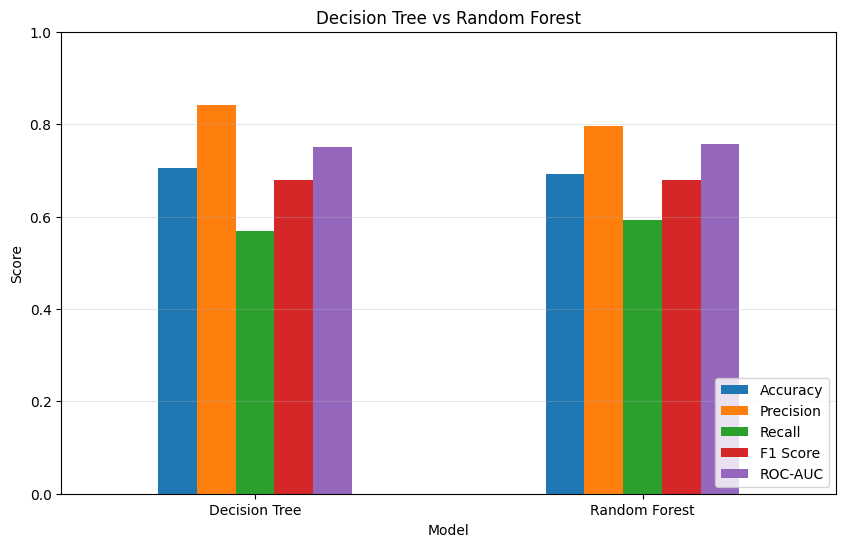

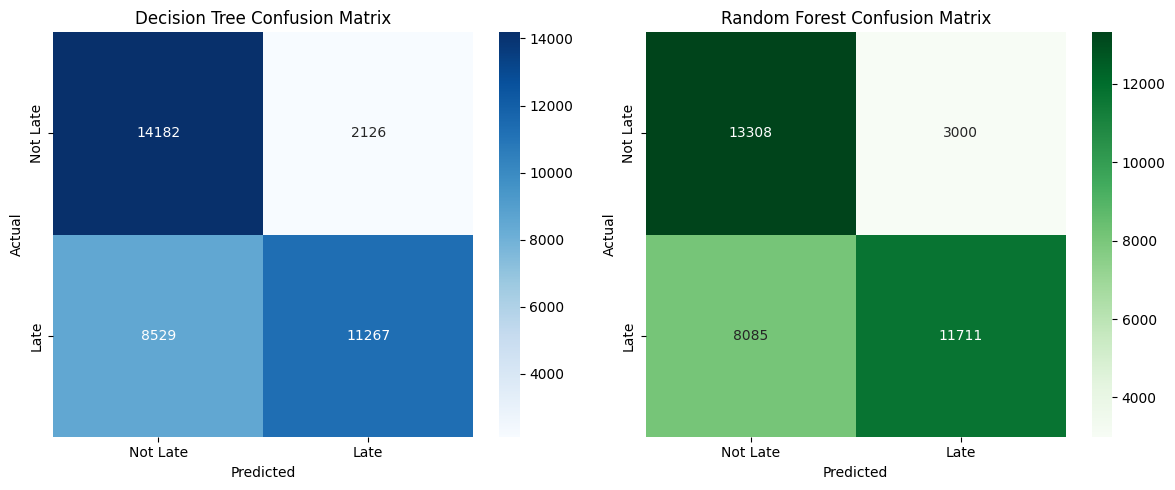

In [9]:
# STEP 7: Model evaluation and comparison

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [dt_accuracy, rf_accuracy],
    'Precision': [dt_precision, rf_precision],
    'Recall': [dt_recall, rf_recall],
    'F1 Score': [dt_f1, rf_f1],
    'ROC-AUC': [dt_auc, rf_auc]
})

print("Model Comparison")
display(
    comparison.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

comparison.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

dt_cm = confusion_matrix(y_test, dt_pred)
rf_cm = confusion_matrix(y_test, rf_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0],
    xticklabels=['Not Late', 'Late'],
    yticklabels=['Not Late', 'Late']
)

axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1],
    xticklabels=['Not Late', 'Late'],
    yticklabels=['Not Late', 'Late']
)

axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Top 20 Decision Tree Features:


,Feature,Importance
5659,categorical__Shipping Mode_Standard Class,0.700747
5657,categorical__Shipping Mode_Same Day,0.120023
5658,categorical__Shipping Mode_Second Class,0.051086
3,categorical__Type_TRANSFER,0.031101
5663,numerical__Latitude,0.010367
5664,numerical__Longitude,0.007948
5676,numerical__order_day,0.007446
5675,numerical__order_month,0.004990
5677,numerical__order_dayofweek,0.004516
5674,numerical__order_year,0.002106


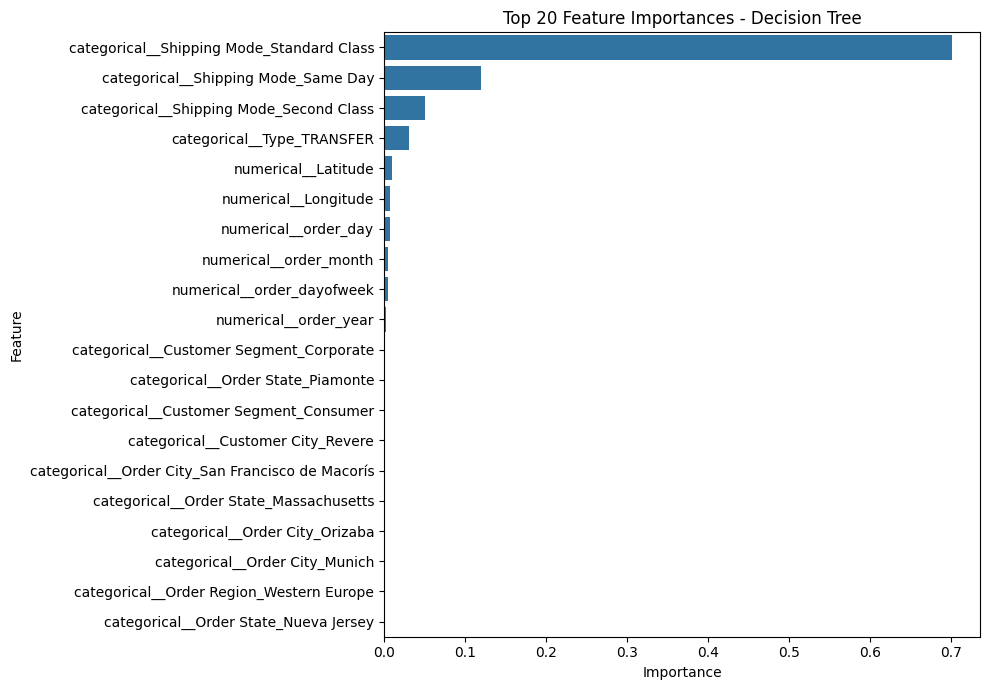


Sample Prediction
-----------------
Actual Late Delivery Risk : 0
Predicted Late Delivery Risk : 0
Probability of Late Delivery : 39.44%
Prediction: Expected On-Time Delivery

Final Project Summary
---------------------
Problem Type : Binary Classification
Target       : Late_delivery_risk
Baseline     : Decision Tree Classifier
Comparison   : Random Forest Classifier
Decision Tree Accuracy : 70.49%
Random Forest Accuracy : 69.30%
Decision Tree ROC-AUC : 74.99%
Random Forest ROC-AUC : 75.64%


In [10]:
# STEP 8: Feature importance and final prediction

dt_classifier = dt_model.named_steps['classifier']
dt_preprocessor = dt_model.named_steps['preprocessor']

feature_names = dt_preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt_classifier.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
).head(20)

print("Top 20 Decision Tree Features:")
display(importance)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Top 20 Feature Importances - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

sample = X_test.iloc[[0]]

actual_value = y_test.iloc[0]
predicted_value = dt_model.predict(sample)[0]
probability = dt_model.predict_proba(sample)[0][1]

print("\nSample Prediction")
print("-----------------")
print("Actual Late Delivery Risk :", actual_value)
print("Predicted Late Delivery Risk :", predicted_value)
print(f"Probability of Late Delivery : {probability:.2%}")

if predicted_value == 1:
    print("Prediction: Potential Late Delivery")
else:
    print("Prediction: Expected On-Time Delivery")

print("\nFinal Project Summary")
print("---------------------")
print("Problem Type : Binary Classification")
print("Target       : Late_delivery_risk")
print("Baseline     : Decision Tree Classifier")
print("Comparison   : Random Forest Classifier")
print(f"Decision Tree Accuracy : {dt_accuracy:.2%}")
print(f"Random Forest Accuracy : {rf_accuracy:.2%}")
print(f"Decision Tree ROC-AUC : {dt_auc:.2%}")
print(f"Random Forest ROC-AUC : {rf_auc:.2%}")